In [1]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import AxesGrid
from salvaged import *
from scaling import *
import dispatch_utils as du
import dispatch_data as dd
# ==========================================
ThisPatch = dd.Stagger2eMHDPatch
run = 'm3r27t05'             # experiment name
datadir = '../data'      # location of the data
gamma = 1.4

using cgs units


In [2]:
snapshot = 7
pp=du.patches(run=run,data=datadir,ThisPatch=ThisPatch)
pp=[p for p in pp if p.iout==snapshot]
for p in pp:
        ul = np.zeros(3)
        ll=list(p.llc)
        for i in range(3):
            #ll[i] = p.pos[i] - p.dx[i]*0.5*p.n[i]
            ul[i] = p.llc[i] + p.dx[i]*float(p.n[i])
        #p.llc=tuple(ll)
        p.urc=tuple(ul)
        p.gamma = gamma
        p.cache()
        p.vars()
        p.strip()
refine_by = 3
to_skip = []
verbose=False
gamma = 1.4
orbit_radius_au = 1.0
omega = [0.0,0.0,1.0]
omega[2] = omega[2]*2.*np.pi*sc.t/cgs.yr
pl_pos= [0.0,1.0,0.0]    
#patches = get_data(snap = snapshot,datadir=datadir, ThisPatch=ThisPatch, skip=to_skip)

216 patches with 8 snapshots found


yt : [INFO     ] 2017-04-21 10:24:54,737 Parameters: current_time              = 140.0
yt : [INFO     ] 2017-04-21 10:24:54,928 Parameters: domain_dimensions         = [48 48 48]
yt : [INFO     ] 2017-04-21 10:24:54,940 Parameters: domain_left_edge          = [ -3395.3175007 -16976.587503   -3395.3175007]
yt : [INFO     ] 2017-04-21 10:24:54,948 Parameters: domain_right_edge         = [  3395.31750063  16976.58750343   3395.31750063]
yt : [INFO     ] 2017-04-21 10:24:54,957 Parameters: cosmological_simulation   = 0.0
yt : [INFO     ] 2017-04-21 10:24:55,984 xlim = -3139.224612 3139.224612
yt : [INFO     ] 2017-04-21 10:24:55,985 ylim = -6278.449223 6278.449223
yt : [INFO     ] 2017-04-21 10:24:55,987 xlim = -3139.224612 3139.224612
yt : [INFO     ] 2017-04-21 10:24:55,988 ylim = -6278.449223 6278.449223
yt : [INFO     ] 2017-04-21 10:24:55,989 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



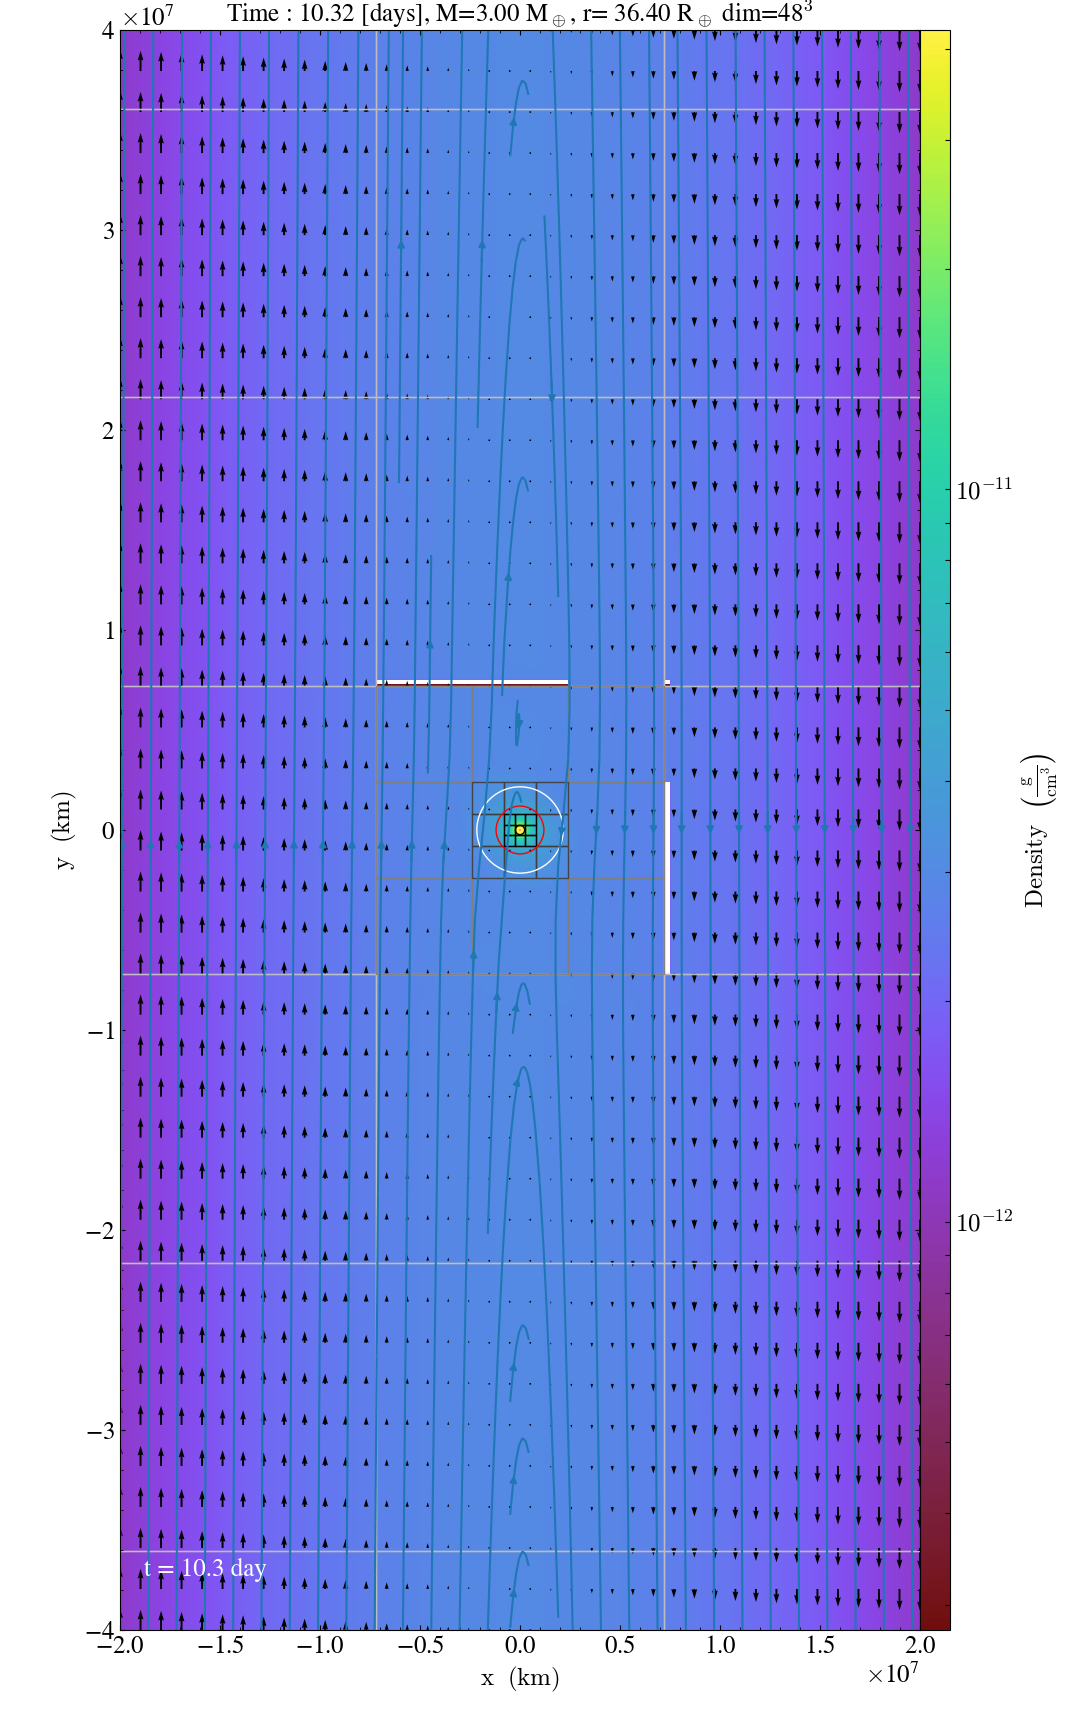

In [5]:
dic=make_yt_dict(pp)
n=pp[0].n
bbox=pp[0].bbox
sz=10000
pl_rad=1.3480656
#pl_rad=1.0
#pl_rad = 0.5376369
rad_mult = 27.0
pl_rad = pl_rad * rad_mult
pl_mass=3.0
csound=1.0
restart_time = 0.
time = pp[0].time+restart_time
bond_rad = pl_mass*sc.g/csound**2
hill_rad = (pl_mass*sc.g/(3.*omega[2]**2))**0.333333
ds = load_yt(dic,n,bbox=bbox, time=time, refine_by=refine_by)

slc=yt.SlicePlot(ds=ds,axis="z",fields=["density"],center=[0,0,0],width = ((4e7,'km'),(8e7,'km')))
# == Annotate velocity quivers and streamlines. ==
slc.annotate_velocity(factor=20, normalize=False)
slc.annotate_streamlines('velocity_x', 'velocity_y', factor=20,field_color=None)
# == A bunch of spheres, representing different radii
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=1, circle_args={'color':'magenta'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=pl_rad, circle_args={'color':'black'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=bond_rad, circle_args={'color':'red'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=hill_rad, circle_args={'color':'white'})
# == TITLE ==
slc.annotate_title("Time : {:.2f} [days], M={:.2f} M$_\oplus$, r= {:.2f} R$_\oplus$ dim={:d}$^3$".format((pp[0].time+restart_time)*sc.t/3600./24., pl_mass, pl_rad, int(n[0])))
#slc.set_zlim('density',6e-12,3e-11)
# == Timestamp ==
slc.current_time=pp[0].time*sc.t/3600./24.
slc.annotate_timestamp()
#slc.zoom(10)
slc.annotate_grids(alpha=0.9, draw_ids=False)
#slc.annotate_timestamp()
slc.show()

yt : [INFO     ] 2017-04-21 10:26:32,068 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



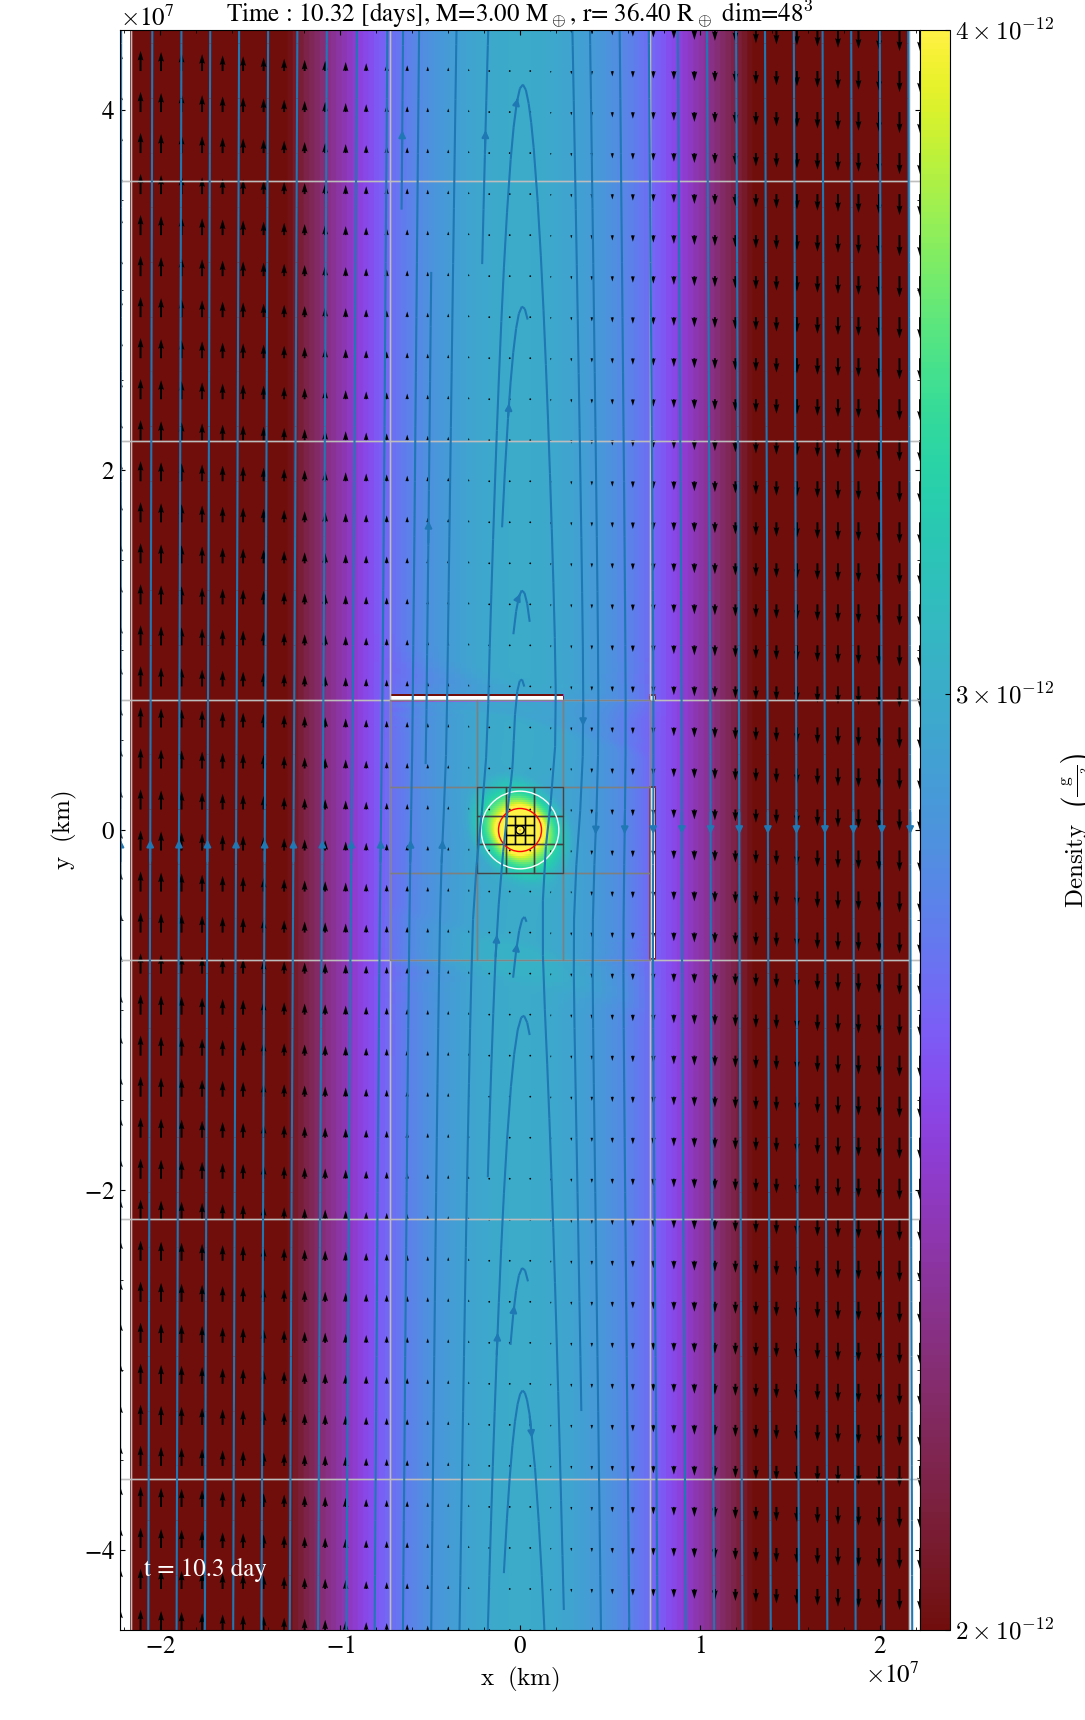

In [9]:
slc.zoom(3)
#slc.set_zlim('temperature',100,2000)
#slc.set_zlim('density',2e-12,4e-12)
#slc.set_zlim('e',8e-14,2e-11)
#slc.annotate_grids()
slc.show()

In [38]:
def load_long_yt(dc,nx,sz=100,refine_by=3,geometry="cartesian",mass_unit=sc.scaling().m,length_unit=sc.scaling().l,
            time_unit=sc.scaling().t,velocity_unit=sc.scaling().v,periodicity=(False,False,False),time=0):
    ds=yt.load_amr_grids(dc,nx,
                       bbox=np.array([[-sz,sz],[-sz*3,sz*3],[-sz,sz]]),
                       refine_by=3,
                       geometry="cartesian",
                       mass_unit=sc.scaling().m,
                       length_unit=(sc.scaling().l,"km"),
                       velocity_unit=sc.scaling().v,
                       time_unit=sc.scaling().t,
                       sim_time = time,
                       periodicity=(False,False,False))
    return ds

In [ ]:
my_ray = ds.ortho_ray(0,(0,0))
ray_sort = np.argsort(my_ray["t"])
density = my_ray["density"][ray_sort]

yt : [INFO     ] 2017-04-07 16:53:50,071 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



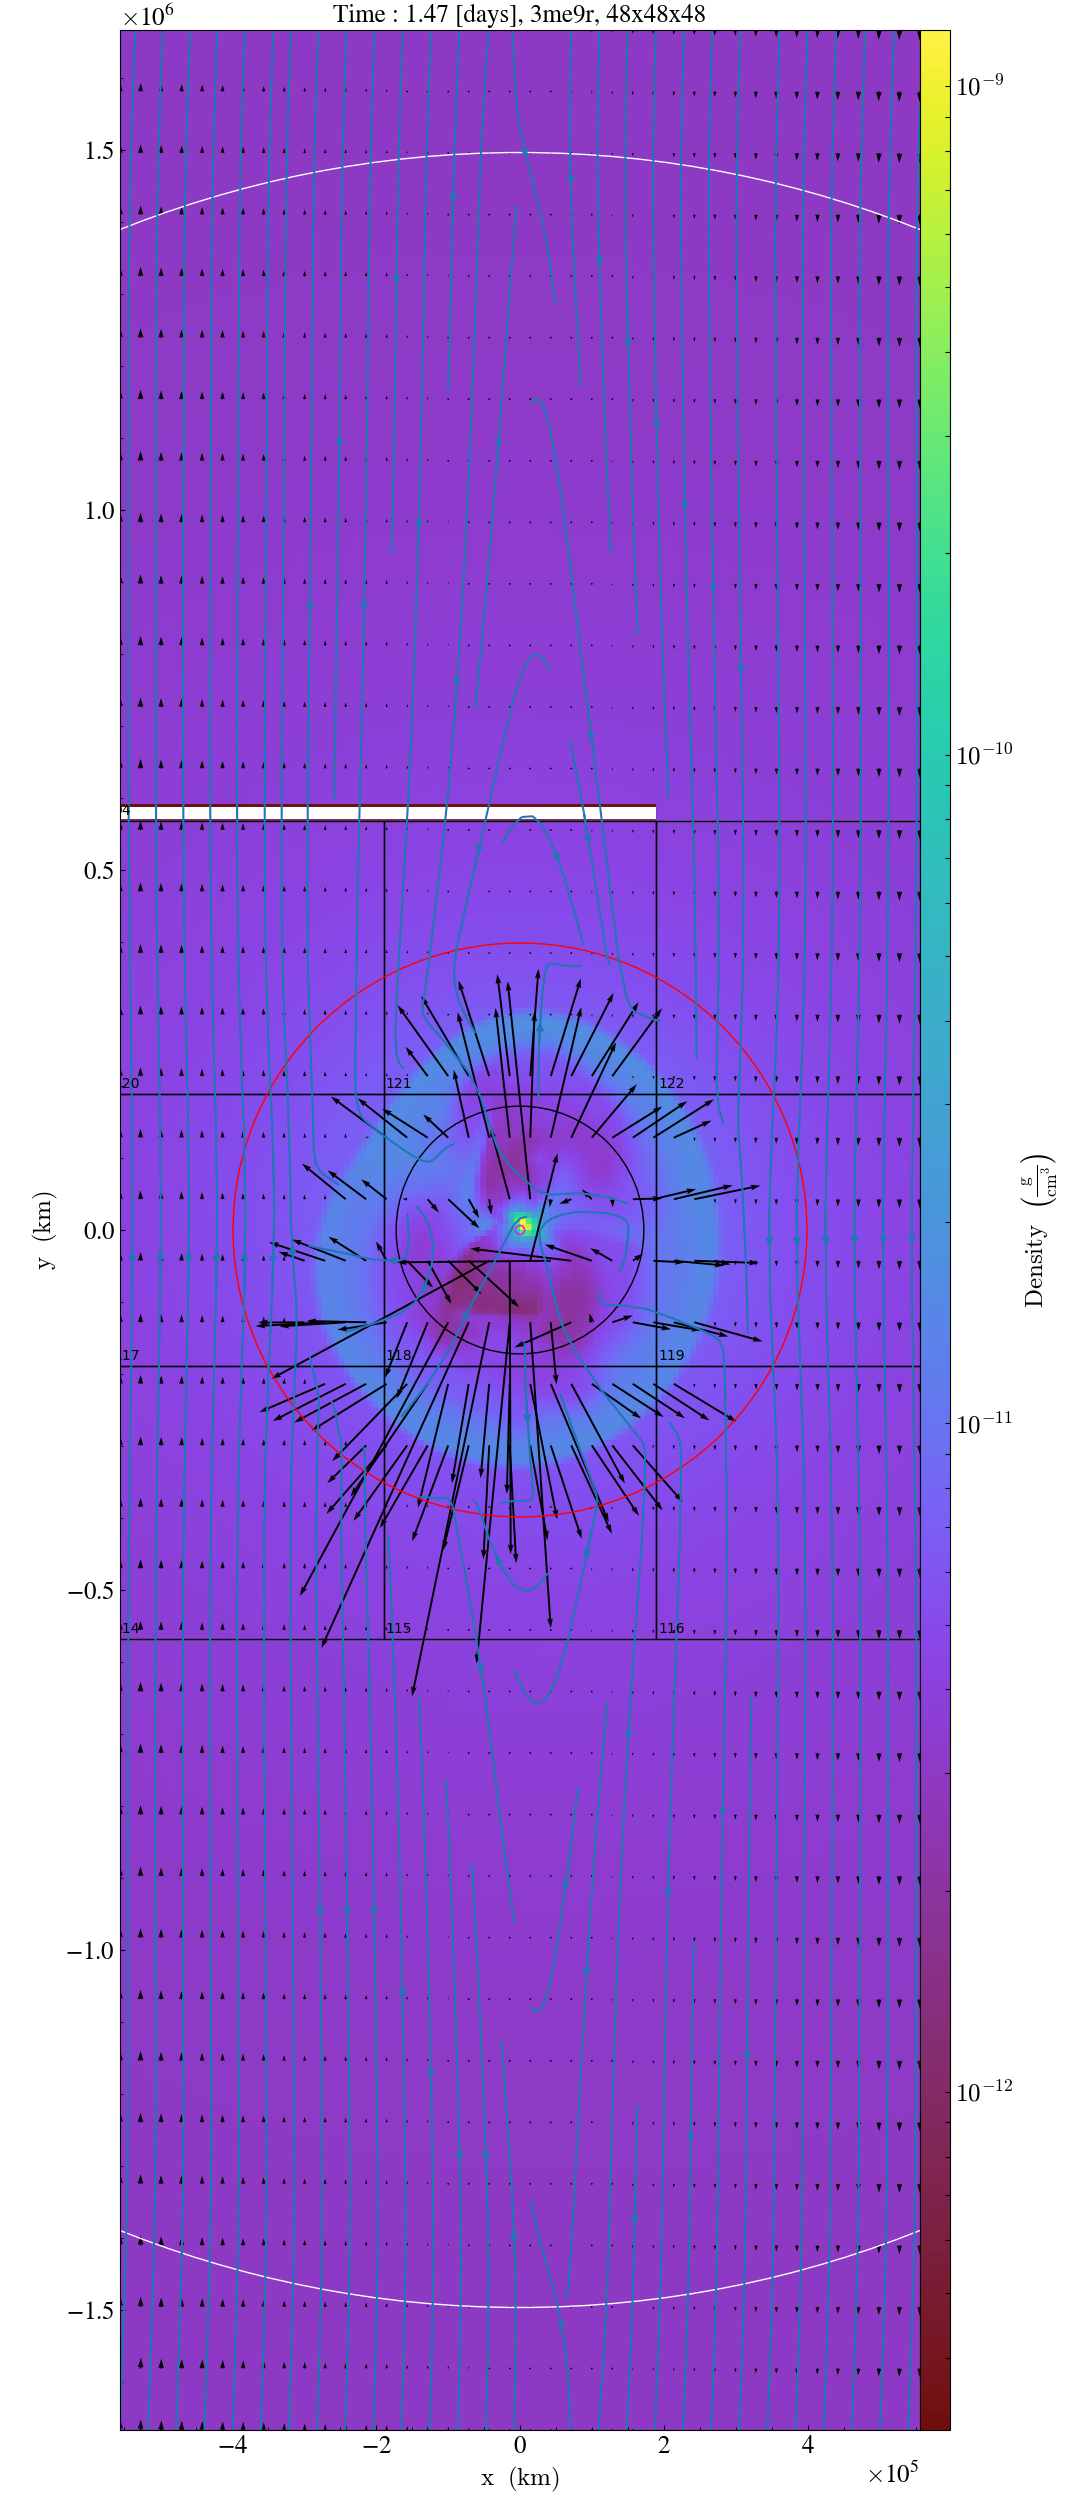

In [116]:
slc.zoom(3)
#slc.set_zlim('temperature',150,250)
#slc.set_zlim('density',2.5e-12,3.5e-12)
#slc.set_zlim('e',8e-14,2e-11)
#slc.annotate_grids()
slc.show()

In [13]:
patches[0].varidx

{'b1': 5,
 'b2': 6,
 'b3': 7,
 'd': 0,
 'e': 1,
 'p1': 2,
 'p2': 3,
 'p3': 4,
 'v1': 8,
 'v2': 9,
 'v3': 10}

In [6]:
sc.scaling().temp

242.2828999782719

In [16]:
ee=ds.all_data()

In [120]:
patches[0].velx.max()

3.2248369308263136e-08

In [12]:
gn =patches[0].gn; ng = patches[0].nghost

In [13]:
u=[a-b for a,b in zip(gn,ng)]

In [21]:
om = omega[2] * np.pi* sc.scaling().t / sc.yr
d0 = 3e-12

om

In [68]:
patches[0].time

1080.0

In [107]:
patches[114].id

119

In [1]:
%gui qt
#%load_ext imayavi


In [1]:
# Create the data.
from numpy import pi, sin, cos, mgrid
dphi, dtheta = pi/250.0, pi/250.0
[phi,theta] = mgrid[0:pi+dphi*1.5:dphi,0:2*pi+dtheta*1.5:dtheta]
m0 = 4; m1 = 3; m2 = 2; m3 = 3; m4 = 6; m5 = 2; m6 = 6; m7 = 4;
r = sin(m0*phi)**m1 + cos(m2*phi)**m3 + sin(m4*theta)**m5 + cos(m6*theta)**m7
x = r*sin(phi)*cos(theta)
y = r*cos(phi)
z = r*sin(phi)*sin(theta)

In [2]:
# View it.
from mayavi import mlab
mlab.mesh(x, y, z)
mlab.show()
#imayavi_show_window(mlab.gcf)

In [5]:
from yx_midplane import *

In [6]:

iout=0
vars=['logd','ux','uy','uz','loge']
for var in vars:
    yx_midplane(run,datadir,iout=iout,var=var)

TypeError: patches() got an unexpected keyword argument 'dir'